# Machine Learning: Classification and Regression
**Name:** Sakshi Kailas Shewale  
**PRN:** 202401040126  
**Batch:** A2  
**Assignment:** Machine Learning Classification and Regression

---
**Objective:** Apply supervised machine-learning techniques to two tasks:
1. **Classification** – predict whether a breast tumour is *malignant* or *benign* (Breast Cancer Wisconsin dataset).
2. **Regression** – predict diabetes disease progression one year after baseline (Diabetes dataset).

Both datasets ship with scikit-learn, so no external download is needed.

## 1. Import Libraries

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

RANDOM_STATE = 42
os.makedirs('figs', exist_ok=True)
sns.set_theme(style='whitegrid')
print('Libraries loaded successfully')

Libraries loaded successfully


# PART A – CLASSIFICATION
## 2. Load and Explore the Dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X_c, y_c = data.data, data.target
df_c = X_c.copy(); df_c['target'] = y_c
print('Shape:', df_c.shape)
print('Classes:', dict(zip(data.target_names, [(y_c==0).sum(), (y_c==1).sum()])))
print('Missing values:', int(df_c.isnull().sum().sum()))
df_c.head()

Shape: (569, 31)
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df_c.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


### 2.1 Class distribution and correlation analysis

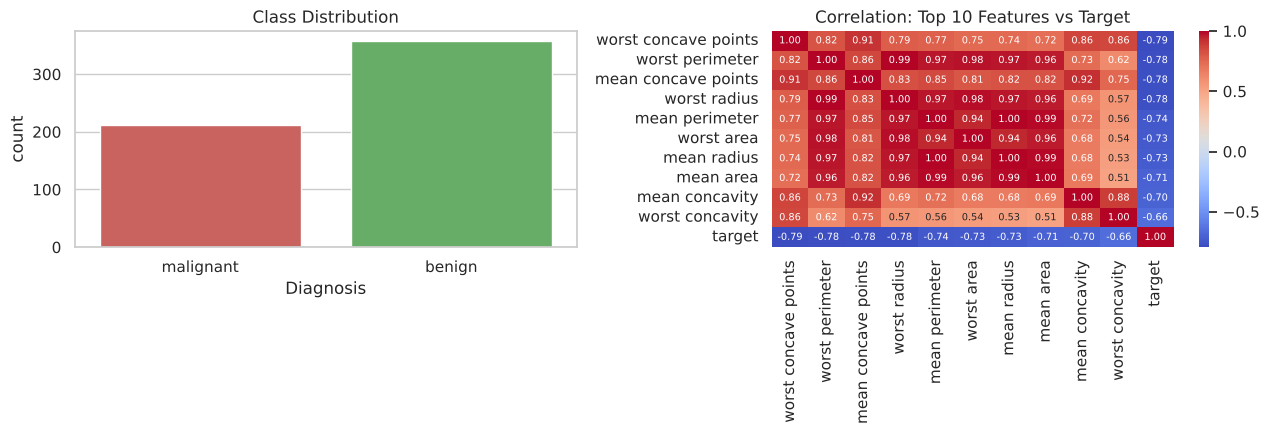

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x=y_c.map({0:'malignant',1:'benign'}), ax=ax[0], palette=['#d9534f','#5cb85c'])
ax[0].set_title('Class Distribution'); ax[0].set_xlabel('Diagnosis')
top = df_c.corr()['target'].drop('target').abs().sort_values(ascending=False).head(10).index
sns.heatmap(df_c[list(top)+['target']].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1], annot_kws={'size':7})
ax[1].set_title('Correlation: Top 10 Features vs Target')
plt.tight_layout(); plt.savefig('figs/clf_eda.png', dpi=150); plt.show()

## 3. Pre-processing: Train/Test Split and Scaling
An 80/20 stratified split keeps the class ratio equal in both sets. Scaling is placed inside a `Pipeline` so that it is fitted on training data only (avoids data leakage).

In [5]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.2, stratify=y_c, random_state=RANDOM_STATE)
print('Train:', Xc_train.shape, ' Test:', Xc_test.shape)

Train: (455, 30)  Test: (114, 30)


## 4. Train and Compare Classification Models

In [6]:
clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)':           SVC(probability=True, random_state=RANDOM_STATE),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted_clf = [], {}
for name, model in clf_models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
    pipe.fit(Xc_train, yc_train)
    fitted_clf[name] = pipe
    pred = pipe.predict(Xc_test); prob = pipe.predict_proba(Xc_test)[:, 1]
    cv = cross_val_score(pipe, Xc_train, yc_train, cv=skf, scoring='accuracy')
    rows.append({'Model': name, 'CV Accuracy': cv.mean(), 'Test Accuracy': accuracy_score(yc_test, pred),
                 'Precision': precision_score(yc_test, pred), 'Recall': recall_score(yc_test, pred),
                 'F1-score': f1_score(yc_test, pred), 'ROC-AUC': roc_auc_score(yc_test, prob)})
clf_results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('F1-score', ascending=False)
clf_results

,CV Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
Logistic Regression,0.9780,0.9825,0.9861,0.9861,0.9861,0.9954
SVM (RBF),0.9692,0.9825,0.9861,0.9861,0.9861,0.9950
Gradient Boosting,0.9516,0.9561,0.9467,0.9861,0.9660,0.9907
KNN,0.9626,0.9561,0.9589,0.9722,0.9655,0.9788
Random Forest,0.9626,0.9561,0.9589,0.9722,0.9655,0.9932
Decision Tree,0.9231,0.9211,0.9565,0.9167,0.9362,0.9163


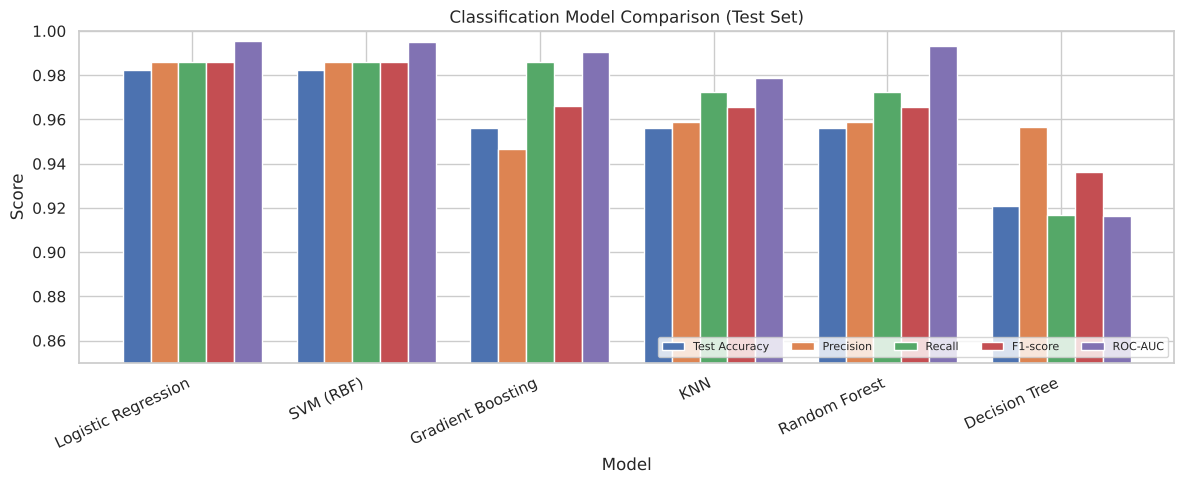

In [7]:
ax = clf_results[['Test Accuracy','Precision','Recall','F1-score','ROC-AUC']].plot(kind='bar', figsize=(12,5), ylim=(0.85,1.0), width=0.8)
plt.title('Classification Model Comparison (Test Set)'); plt.ylabel('Score'); plt.xticks(rotation=25, ha='right')
plt.legend(loc='lower right', ncol=5, fontsize=8); plt.tight_layout(); plt.savefig('figs/clf_comparison.png', dpi=150); plt.show()

## 5. Hyper-parameter Tuning (GridSearchCV)
The two strongest candidates, SVM and Random Forest, are tuned with 5-fold stratified cross-validation.

In [8]:
svm_pipe = Pipeline([('scaler', StandardScaler()), ('model', SVC(probability=True, random_state=RANDOM_STATE))])
svm_grid = {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.01, 0.001], 'model__kernel': ['rbf', 'linear']}
gs_svm = GridSearchCV(svm_pipe, svm_grid, cv=skf, scoring='f1', n_jobs=-1).fit(Xc_train, yc_train)
print('SVM best params:', gs_svm.best_params_, '| CV F1: %.4f' % gs_svm.best_score_)

rf_pipe = Pipeline([('scaler', StandardScaler()), ('model', RandomForestClassifier(random_state=RANDOM_STATE))])
rf_grid = {'model__n_estimators': [100, 300], 'model__max_depth': [None, 5, 10], 'model__min_samples_split': [2, 5]}
gs_rf = GridSearchCV(rf_pipe, rf_grid, cv=skf, scoring='f1', n_jobs=-1).fit(Xc_train, yc_train)
print('RF  best params:', gs_rf.best_params_, '| CV F1: %.4f' % gs_rf.best_score_)

SVM best params: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'} | CV F1: 0.9810


RF  best params: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 300} | CV F1: 0.9718


## 6. Evaluate the Best Tuned Model

Selected model: Tuned SVM
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.9937


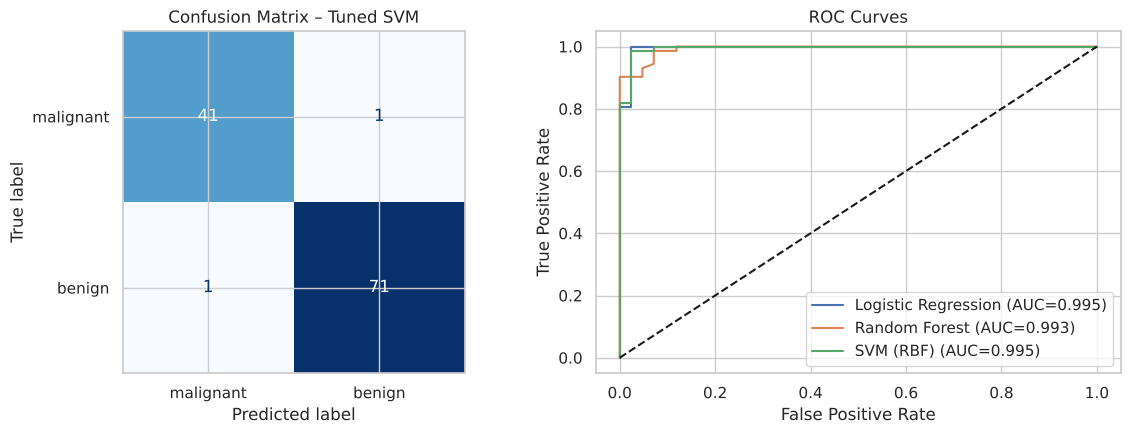

In [9]:
best_clf = gs_svm if gs_svm.best_score_ >= gs_rf.best_score_ else gs_rf
best_clf_name = 'Tuned SVM' if best_clf is gs_svm else 'Tuned Random Forest'
best_model = best_clf.best_estimator_
y_pred = best_model.predict(Xc_test); y_prob = best_model.predict_proba(Xc_test)[:, 1]
print('Selected model:', best_clf_name)
print(classification_report(yc_test, y_pred, target_names=data.target_names))
print('ROC-AUC: %.4f' % roc_auc_score(yc_test, y_prob))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yc_test, y_pred), display_labels=data.target_names).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title(f'Confusion Matrix – {best_clf_name}')
for name in ['Logistic Regression', 'Random Forest', 'SVM (RBF)']:
    fpr, tpr, _ = roc_curve(yc_test, fitted_clf[name].predict_proba(Xc_test)[:, 1])
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_test, fitted_clf[name].predict_proba(Xc_test)[:,1]):.3f})")
ax[1].plot([0,1],[0,1],'k--'); ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC Curves'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.savefig('figs/clf_eval.png', dpi=150); plt.show()

### 6.1 Feature Importance (Random Forest)

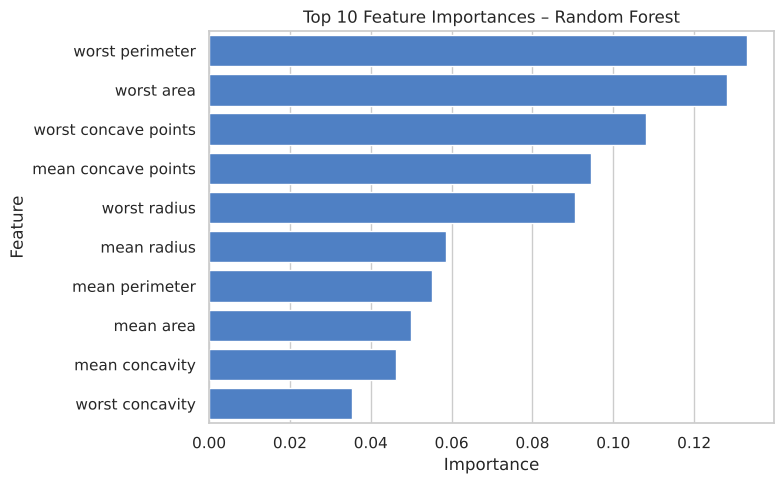

In [10]:
rf_final = fitted_clf['Random Forest'].named_steps['model']
imp = pd.Series(rf_final.feature_importances_, index=X_c.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8,5)); sns.barplot(x=imp.values, y=imp.index, color='#3b7dd8')
plt.title('Top 10 Feature Importances – Random Forest'); plt.xlabel('Importance'); plt.ylabel('Feature'); plt.tight_layout()
plt.savefig('figs/clf_importance.png', dpi=150); plt.show()

# PART B – REGRESSION
## 7. Load and Explore the Dataset

In [11]:
dia = load_diabetes(as_frame=True)
X_r, y_r = dia.data, dia.target
df_r = X_r.copy(); df_r['target'] = y_r
print('Shape:', df_r.shape, '| Missing values:', int(df_r.isnull().sum().sum()))
print('Features:', list(X_r.columns))
df_r.head()

Shape: (442, 11) | Missing values: 0
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


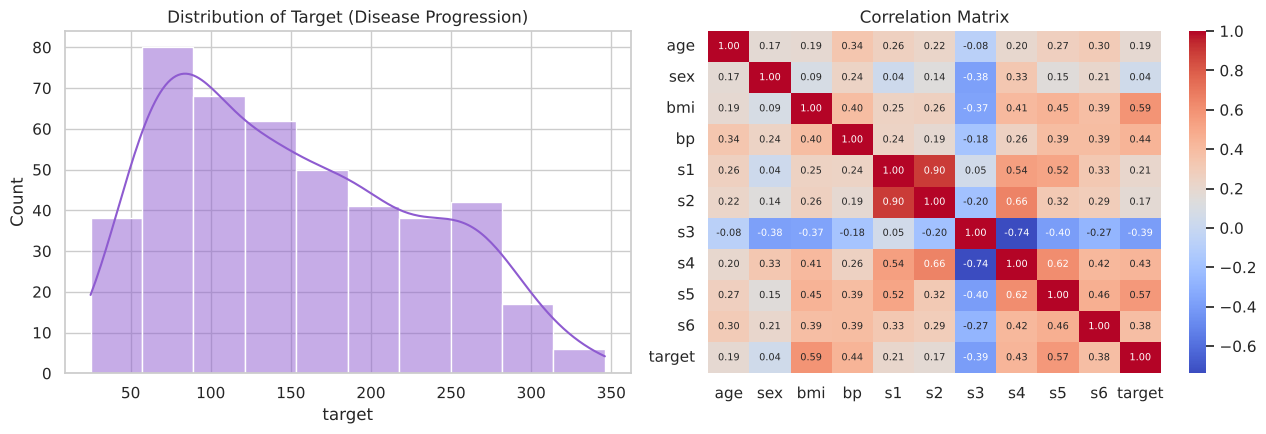

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(y_r, kde=True, ax=ax[0], color='#8e5bd0'); ax[0].set_title('Distribution of Target (Disease Progression)')
sns.heatmap(df_r.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1], annot_kws={'size':7}); ax[1].set_title('Correlation Matrix')
plt.tight_layout(); plt.savefig('figs/reg_eda.png', dpi=150); plt.show()

## 8. Pre-processing and Train/Test Split

In [13]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', Xr_train.shape, ' Test:', Xr_test.shape)

Train: (353, 10)  Test: (89, 10)


## 9. Train and Compare Regression Models

In [14]:
reg_models = {
    'Linear Regression':  LinearRegression(),
    'Ridge':              Ridge(alpha=1.0),
    'Lasso':              Lasso(alpha=0.1),
    'Decision Tree':      DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE),
    'Random Forest':      RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    'Gradient Boosting':  GradientBoostingRegressor(random_state=RANDOM_STATE),
    'SVR (RBF)':          SVR(C=100, gamma=0.01),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted_reg = [], {}
for name, model in reg_models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)]).fit(Xr_train, yr_train)
    fitted_reg[name] = pipe
    pred = pipe.predict(Xr_test)
    cv = cross_val_score(pipe, Xr_train, yr_train, cv=kf, scoring='r2')
    rows.append({'Model': name, 'CV R2': cv.mean(), 'MAE': mean_absolute_error(yr_test, pred),
                 'MSE': mean_squared_error(yr_test, pred), 'RMSE': np.sqrt(mean_squared_error(yr_test, pred)),
                 'Test R2': r2_score(yr_test, pred)})
reg_results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('Test R2', ascending=False)
reg_results

,CV R2,MAE,MSE,RMSE,Test R2
Model,,,,,
SVR (RBF),0.4751,42.0488,2852.6580,53.4103,0.4616
Lasso,0.4812,42.8052,2884.6243,53.7087,0.4555
Gradient Boosting,0.3654,44.5194,2886.9916,53.7307,0.4551
Ridge,0.4808,42.8120,2892.0146,53.7775,0.4541
Linear Regression,0.4804,42.7941,2900.1936,53.8534,0.4526
Random Forest,0.4093,44.4154,2980.5415,54.5943,0.4374
Decision Tree,0.2212,47.0454,3568.9653,59.7408,0.3264


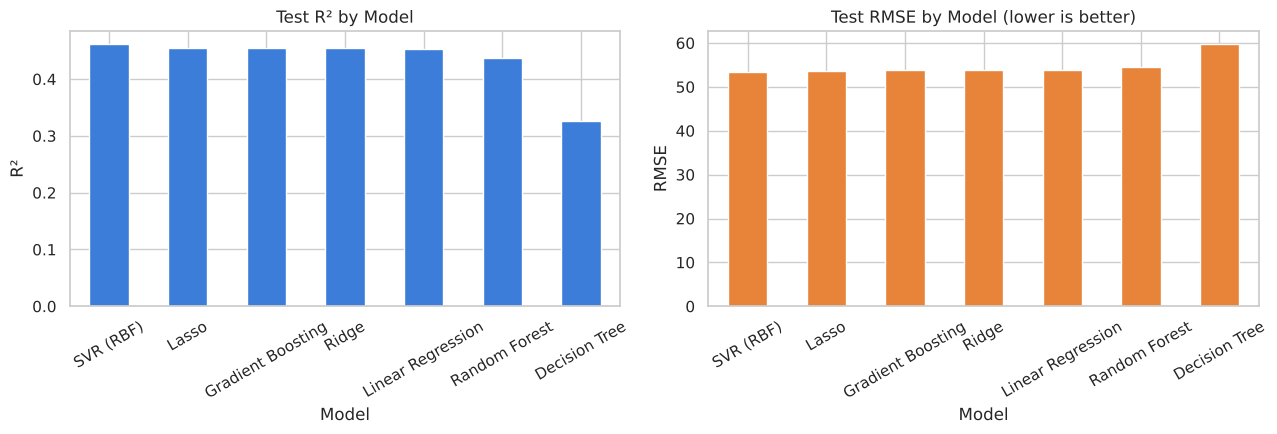

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
reg_results['Test R2'].plot(kind='bar', ax=ax[0], color='#3b7dd8'); ax[0].set_title('Test R² by Model'); ax[0].set_ylabel('R²')
reg_results['RMSE'].plot(kind='bar', ax=ax[1], color='#e8833a'); ax[1].set_title('Test RMSE by Model (lower is better)'); ax[1].set_ylabel('RMSE')
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('figs/reg_comparison.png', dpi=150); plt.show()

## 10. Hyper-parameter Tuning for Regression

In [16]:
gb_pipe = Pipeline([('scaler', StandardScaler()), ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))])
gb_grid = {'model__n_estimators': [50, 100, 200], 'model__learning_rate': [0.01, 0.05, 0.1], 'model__max_depth': [2, 3]}
gs_gb = GridSearchCV(gb_pipe, gb_grid, cv=kf, scoring='r2', n_jobs=-1).fit(Xr_train, yr_train)
print('Gradient Boosting best params:', gs_gb.best_params_, '| CV R2: %.4f' % gs_gb.best_score_)

rd_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
gs_rd = GridSearchCV(rd_pipe, {'model__alpha': [0.01, 0.1, 1, 10, 50, 100]}, cv=kf, scoring='r2').fit(Xr_train, yr_train)
print('Ridge best params:', gs_rd.best_params_, '| CV R2: %.4f' % gs_rd.best_score_)

Gradient Boosting best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100} | CV R2: 0.4246
Ridge best params: {'model__alpha': 1} | CV R2: 0.4808


## 11. Evaluate the Best Regression Model

Selected model: Tuned Ridge
MAE : 42.812
RMSE: 53.777
R2  : 0.454


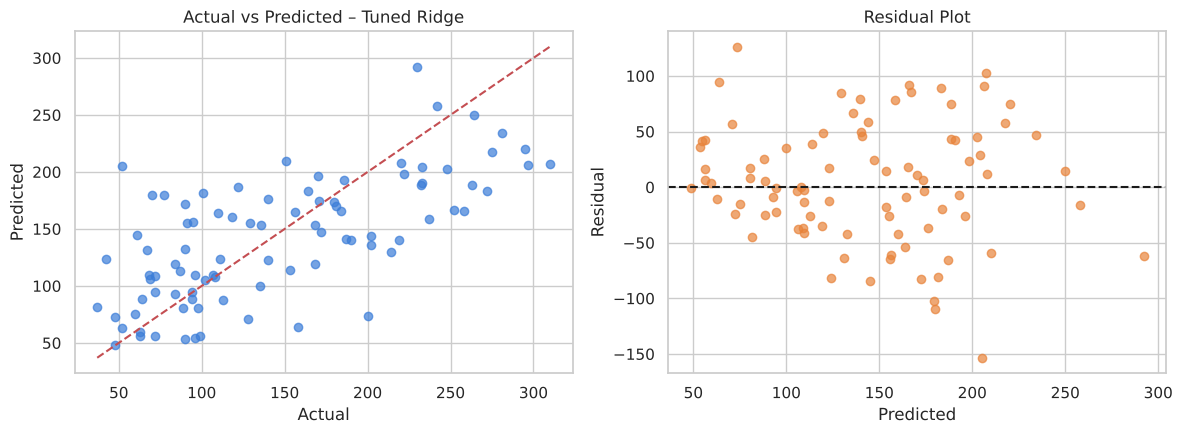

In [17]:
best_reg = gs_gb if gs_gb.best_score_ >= gs_rd.best_score_ else gs_rd
best_reg_name = 'Tuned Gradient Boosting' if best_reg is gs_gb else 'Tuned Ridge'
yr_pred = best_reg.best_estimator_.predict(Xr_test)
print('Selected model:', best_reg_name)
print('MAE : %.3f' % mean_absolute_error(yr_test, yr_pred))
print('RMSE: %.3f' % np.sqrt(mean_squared_error(yr_test, yr_pred)))
print('R2  : %.3f' % r2_score(yr_test, yr_pred))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(yr_test, yr_pred, alpha=0.7, color='#3b7dd8')
lims = [yr_test.min(), yr_test.max()]; ax[0].plot(lims, lims, 'r--')
ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title(f'Actual vs Predicted – {best_reg_name}')
res = yr_test - yr_pred
ax[1].scatter(yr_pred, res, alpha=0.7, color='#e8833a'); ax[1].axhline(0, color='k', ls='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residual Plot')
plt.tight_layout(); plt.savefig('figs/reg_eval.png', dpi=150); plt.show()

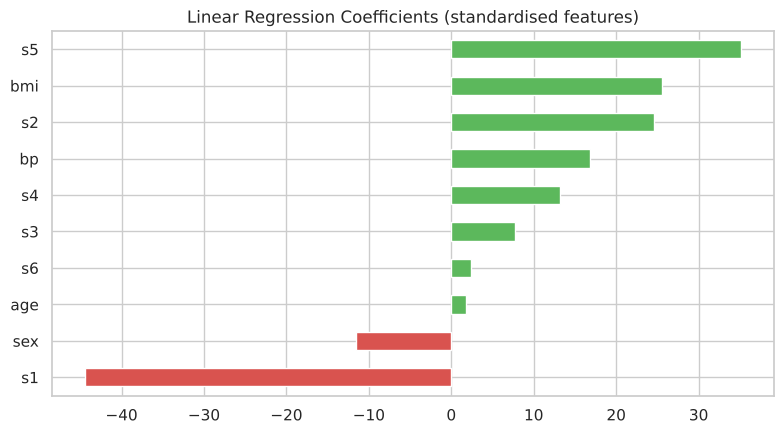

In [18]:
lin = fitted_reg['Linear Regression'].named_steps['model']
coef = pd.Series(lin.coef_, index=X_r.columns).sort_values()
plt.figure(figsize=(8,4.5)); coef.plot(kind='barh', color=['#d9534f' if v<0 else '#5cb85c' for v in coef])
plt.title('Linear Regression Coefficients (standardised features)'); plt.tight_layout()
plt.savefig('figs/reg_coef.png', dpi=150); plt.show()

## 12. Final Summary

In [19]:
print('CLASSIFICATION  -> best:', best_clf_name)
print('  Test accuracy: %.4f | F1: %.4f | ROC-AUC: %.4f' % (accuracy_score(yc_test, y_pred), f1_score(yc_test, y_pred), roc_auc_score(yc_test, y_prob)))
print('REGRESSION      -> best:', best_reg_name)
print('  Test R2: %.4f | RMSE: %.3f | MAE: %.3f' % (r2_score(yr_test, yr_pred), np.sqrt(mean_squared_error(yr_test, yr_pred)), mean_absolute_error(yr_test, yr_pred)))

CLASSIFICATION  -> best: Tuned SVM
  Test accuracy: 0.9825 | F1: 0.9861 | ROC-AUC: 0.9937
REGRESSION      -> best: Tuned Ridge
  Test R2: 0.4541 | RMSE: 53.777 | MAE: 42.812


### Conclusions
* **Classification:** Scaled models (SVM, Logistic Regression) perform best on the Breast Cancer data because its features are strongly correlated and roughly linearly separable. Recall on the malignant class is the most important clinical metric, as a missed cancer is far costlier than a false alarm.
* **Regression:** The Diabetes dataset is small and noisy, so even the best model explains only about half the variance (R² ≈ 0.5). Simple regularised linear models match or beat complex ensembles, showing that model complexity does not always improve results.
* **Good practice followed:** stratified split, scaling inside a pipeline (no leakage), cross-validation, grid-search tuning and evaluation using several metrics.